# Topic A — L1: Analytic Approximations & Implied Volatility

*FINM 32000 Numerical Methods — Final-Exam Study Notes*

---

**Prerequisite:** Read [Topic 0 — Foundations](Topic-0_Foundations.ipynb) first. This notebook assumes you understand:
- Risk-neutral pricing (Topic 0 §3)
- Black-Scholes formula and what $d_1$, $d_2$ mean (Topic 0 §7–8)
- Delta, gamma, vega (Topic 0 §9)
- Forward prices and put-call parity (Topic 0 §11–12)

**Why this topic matters for the final**

Lecture 1 gives you **shortcut formulas** for mental math and hedging — not a new numerical method. But these shortcuts appear everywhere:
- **Practice-Final Problem 1** is a dollar-gamma rebalancing question (pure L1)
- Sanity-checking tree, finite-difference, and Monte Carlo prices
- Interview-style "price an ATMF option without a calculator"

**Three formulas to memorize from this topic**

| # | Formula | Use |
|---|---|---|
| 1 | ATMF call $\approx 0.4 \cdot S \cdot \sigma \sqrt{T}$ | Quick price estimate |
| 2 | Dollar shares to buy per 1% up-move $\approx S^2 \Gamma / 100$ | Practice-Final P1 |
| 3 | American call = European call (no div, $r > 0$) | Skip LSM for calls |


In [1]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
%matplotlib inline
np.set_printoptions(precision=6, suppress=True)

def bs_call(S, K, T, r, sigma, q=0.0):
    F = S * np.exp((r - q) * T)
    std = sigma * np.sqrt(T)
    d1 = np.log(F / K) / std + std / 2
    d2 = d1 - std
    return np.exp(-r * T) * (F * norm.cdf(d1) - K * norm.cdf(d2))

def bs_delta(S, K, T, r, sigma, q=0.0):
    F = S * np.exp((r - q) * T)
    std = sigma * np.sqrt(T)
    d1 = np.log(F / K) / std + std / 2
    return np.exp(-q * T) * norm.cdf(d1)

def bs_gamma(S, K, T, r, sigma, q=0.0):
    F = S * np.exp((r - q) * T)
    std = sigma * np.sqrt(T)
    d1 = np.log(F / K) / std + std / 2
    return np.exp(-q * T) * norm.pdf(d1) / (S * std)

def bs_vega(S, K, T, r, sigma, q=0.0):
    F = S * np.exp((r - q) * T)
    std = sigma * np.sqrt(T)
    d1 = np.log(F / K) / std + std / 2
    return np.exp(-r * T) * F * np.sqrt(T) * norm.pdf(d1)


## 1. Implied volatility — what it is and why we use it

### The problem implied vol solves

The Black-Scholes formula (Topic 0 §7) gives a call price if you know $\sigma$ (volatility). But in the market, you observe the **price** first. Traders reverse the question:

> **Given the market price $C^{\mathrm{mkt}}$, what volatility $\sigma$ would make Black-Scholes match that price?**

That $\sigma$ is called the **implied volatility** (often written $\sigma_{\mathrm{imp}}$ or just "IV").

### Analogy: bond yield-to-maturity

When you buy a bond, you see its **price** (\$980). You do not see a "yield" printed on it. But you can ask: "What constant interest rate would make the bond's discounted cashflows equal \$980?" That rate is the **yield-to-maturity**.

You do not believe interest rates are literally constant for 10 years. Yield is just a **quoting convention** — a single number that summarizes the price.

Implied volatility works the same way for options. You do not believe the stock follows GBM with constant vol. IV is a **quoting convention** — one number that summarizes the option price.

### Definition (formal)

Given market price $C^{\mathrm{mkt}}$ for a European call with strike $K$ and expiry $T$:
$$
C^{\mathrm{mkt}} = C^{\mathrm{BS}}(S_0, K, T, r, \sigma_{\mathrm{imp}}).
$$
Solve for $\sigma_{\mathrm{imp}}$. It exists and is unique because the BS price increases with $\sigma$ (vega $> 0$).

### Why call implied vol equals put implied vol

From put-call parity (Topic 0 §12): $C - P = e^{-rT}(F_0 - K)$. This relationship holds for **market prices** and for **Black-Scholes prices** at the same $\sigma$. So if $\sigma$ makes the call price match, the same $\sigma$ makes the put price match. One implied vol per strike.


In [2]:
from scipy.optimize import brentq

def implied_vol(C_mkt, S, K, T, r, q=0.0):
    f = lambda s: bs_call(S, K, T, r, s, q) - C_mkt
    return brentq(f, 1e-6, 5.0)

C_market = bs_call(100, 100, 1, 0.05, 0.30)
iv = implied_vol(C_market, 100, 100, 1, 0.05)
print(f"Market price from 30% vol model: {C_market:.4f}")
print(f"Implied vol recovered:           {iv:.4f}")


Market price from 30% vol model: 14.2313
Implied vol recovered:           0.3000


### The volatility smile and skew

If GBM with constant $\sigma$ were true, every option at every strike would have the same implied vol — a flat surface.

In reality, implied vol **varies with strike and expiry**. For equity indices, out-of-the-money puts usually have higher IV than out-of-the-money calls. The plot slopes downward — a **volatility skew**.

**Why does the skew exist? (Three explanations, in plain language)**

1. **Fat tails.** Real stock returns have more extreme moves than a normal distribution predicts. Options that pay off in extreme scenarios (deep OTM puts) are worth more, so their implied vol is higher.

2. **Leverage effect.** When a stock price falls, its volatility tends to rise. So paths that end near low strikes (where puts pay) experience higher volatility along the way. Those puts deserve higher prices, hence higher IV.

3. **Supply and demand.** Institutional investors buy OTM puts for portfolio protection ("insurance"). That demand bids up put prices. Conversely, covered-call writers supply OTM calls, pushing call prices down. Both effects tilt the skew.

For the exam, you rarely compute the full skew. The main computation is HW1 Problem 2(c): sensitivity of one option's price to a change in the skew slope — covered in Section 6.


## 2. American call = European call (no dividends, $r \ge 0$)

### Why this theorem matters

If you can price a **European** call, you automatically know the **American** call price too (under the conditions below). You do not need binomial trees or Longstaff-Schwartz for American calls on non-dividend stocks.

### The theorem

On a stock that pays **no dividends**, with interest rate $r \ge 0$:
$$
\text{American call price} = \text{European call price}.
$$
It is never optimal to exercise an American call early.

### Proof 1 — inequality chain (step by step)

Fix a time $t$ before expiry. Let $Z_t^T$ = price at time $t$ of a discount bond that pays \$1 at time $T$. With continuous rate $r$, $Z_t^T = e^{-r(T-t)} \le 1$ when $r \ge 0$.

Now chain three facts:

**Step 1:** American call $\ge$ European call.
The American can be exercised any time; the European only at $T$. More rights $\Rightarrow$ higher or equal price.

**Step 2:** European call $\ge$ forward value $S_t - K Z_t^T$.
A European call is worth at least as much as a forward with delivery price $K$ (standard lower bound).

**Step 3:** Forward value $> S_t - K$ when $r > 0$.
Because $Z_t^T < 1$, we have $S_t - K Z_t^T > S_t - K$.

**Conclusion:** American call $> S_t - K$ = the payoff from exercising now. So exercising early gives you **less** than the option is worth. Never exercise early.

### Proof 2 — arbitrage (if you prefer a trading argument)

Suppose American costs more than European. Sell the American, buy the European, pocket the difference.

- If the buyer never exercises: you keep the profit, no further cost.
- If the buyer exercises early at time $\tau$: you deliver a share (owe $S_\tau$) but receive \$K cash. That \$K grows to at least \$K by expiry. Your European call pays at least $S_T - K$ at expiry, enough to cover the short stock.

Either way, risk-free profit. Contradiction. So prices must be equal.

### When the theorem fails

| Situation | Why early exercise can be optimal |
|---|---|
| Stock pays dividends | Holding the call means you miss the dividend; exercising captures it |
| Negative interest rates | The bond factor $Z_t^T > 1$ breaks Step 3 |
| American **puts** | No such theorem; deep ITM puts can be worth exercising early to get \$K now |


## 3. Taylor approximation — why we need it and how to use it

### The problem Taylor approximation solves

You are short a call and hedging with $\Delta$ shares of stock (Topic 0 §10). When the stock price moves from $S$ to $S + \varepsilon$, two things happen:
1. The **call price** changes (nonlinearly).
2. The **correct number of shares** $\Delta$ changes too (because delta depends on $S$).

To rebalance the hedge, you need to know: **how many dollars of stock to buy or sell?**

Re-running Black-Scholes at every tick is fine for a computer, but on an exam you need a quick formula. That formula comes from a **Taylor expansion**.

### Second-order expansion of the call price

Treat the call price as a function $C(S)$ of the stock price (holding everything else fixed):
$$
C(S + \varepsilon) = C(S) + \Delta \cdot \varepsilon + \tfrac12 \Gamma \cdot \varepsilon^2 + \text{(smaller terms)}.
$$

**Read this:** The price change has three parts:
- $\Delta \cdot \varepsilon$ = first-order effect (the delta term)
- $\tfrac12 \Gamma \cdot \varepsilon^2$ = curvature correction (the gamma term)
- The rest is negligible for small moves

Differentiating once more gives the **delta expansion**:
$$
\Delta(S + \varepsilon) = \Delta(S) + \Gamma \cdot \varepsilon + \text{(smaller terms)}. \tag{$\star$}
$$

This says: when the stock moves by $\varepsilon$, delta changes by approximately $\Gamma \cdot \varepsilon$.


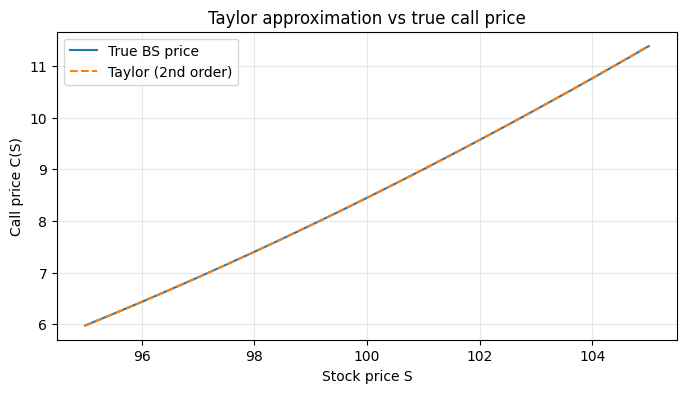

In [3]:
S0, K, T, r, sigma = 100, 100, 0.5, 0.0, 0.30
eps_range = np.linspace(-5, 5, 200)
C0 = bs_call(S0, K, T, r, sigma)
D0 = bs_delta(S0, K, T, r, sigma)
G0 = bs_gamma(S0, K, T, r, sigma)

C_taylor = C0 + D0 * eps_range + 0.5 * G0 * eps_range**2
C_true = [bs_call(S0 + e, K, T, r, sigma) for e in eps_range]

plt.figure(figsize=(8, 4))
plt.plot(S0 + eps_range, C_true, label='True BS price')
plt.plot(S0 + eps_range, C_taylor, '--', label='Taylor (2nd order)')
plt.xlabel('Stock price S')
plt.ylabel('Call price C(S)')
plt.title('Taylor approximation vs true call price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Dollar delta and dollar gamma

| Name | Formula | Meaning |
|---|---|---|
| **Dollar delta** | $S \Delta$ | Dollar value of shares in the delta hedge |
| **Dollar gamma** | $S^2 \Gamma$ | How much dollar delta changes per unit percent move |

**Why $S^2$?** Write the stock move as a **percentage** $x = \varepsilon / S$. Then $\varepsilon = Sx$ and:
$$
\Delta(S(1+x)) - \Delta(S) \approx \Gamma \cdot Sx.
$$
The **number of shares** to buy/sell is $\Gamma Sx$. Their **dollar value** at the new price $S(1+x)$ is:
$$
(\Gamma Sx) \cdot S(1+x) \approx \Gamma S^2 x.
$$

For a **1% move** ($x = 0.01$):
$$
\boxed{\text{Dollars of stock to buy per 1% up-move} \approx \frac{S^2 \Gamma}{100} = \frac{\text{dollar gamma}}{100}.}
$$

**Sign convention:** Positive = buy shares; negative = sell shares.


In [4]:
S0 = 90.0
Gamma_given = 0.015
route1 = S0**2 * Gamma_given / 100
print(f"Practice-Final P1 formula: S^2 * Gamma / 100 = {route1:.5f} dollars")

x = 0.01
S1 = S0 * (1 + x)
route2 = Gamma_given * (S1 - S0) * S1
print(f"Alternative (delta change * new price): {route2:.5f} dollars")
print(f"Small difference (second-order): {route2 - route1:.5f}")


Practice-Final P1 formula: S^2 * Gamma / 100 = 1.21500 dollars
Alternative (delta change * new price): 1.22715 dollars
Small difference (second-order): 0.01215


## 4. Normal approximation for at-the-money-forward (ATMF) options

### What "ATMF" means

**ATMF** = at-the-money **forward** = strike equals the forward price: $K = F_0 = S_0 e^{(r-q)T}$.

This is the natural reference point because the forward is the fair expected delivery price (Topic 0 §11). ATMF options simplify because $\log(F_0/K) = 0$.

### Why ATMF prices have a simple formula

Plug $K = F_0$ into Black-Scholes (Topic 0 §7). Then $d_1 = \sigma\sqrt{T}/2$ and $d_2 = -\sigma\sqrt{T}/2$, and:
$$
C_{\mathrm{ATMF}} = S_0 \bigl[N(\sigma\sqrt{T}/2) - N(-\sigma\sqrt{T}/2)\bigr].
$$

**Why $e^{-rT} F_0 = S_0$:** The forward grows at rate $r$, but we discount at rate $r$. They cancel.

### Taylor expansion of $N$

For small $x$: $N(x) \approx \tfrac12 + x/\sqrt{2\pi}$. With $x = \sigma\sqrt{T}/2$:
$$
N(x) - N(-x) \approx \frac{\sigma\sqrt{T}}{\sqrt{2\pi}}.
$$

So:
$$
\boxed{C_{\mathrm{ATMF}} \approx \frac{S_0 \sigma\sqrt{T}}{\sqrt{2\pi}} \approx 0.4 \cdot S_0 \sigma\sqrt{T}.}
$$

**Example (L1.30 interview question):** $S_0 = 100$, $\sigma = 0.20$, $T = 1$, no div:
$$
C \approx 0.4 \times 100 \times 0.20 \times 1 = 8 \text{ dollars}.
$$
True BS price: about \$7.97.


In [5]:
S0, T, sigma, r = 100, 1.0, 0.20, 0.0
K = S0 * np.exp(r * T)
C_true = bs_call(S0, K, T, r, sigma)
C_approx = 0.4 * S0 * sigma * np.sqrt(T)
C_precise = S0 * sigma * np.sqrt(T) / np.sqrt(2 * np.pi)
print(f"True BS price:     {C_true:.4f}")
print(f"0.4*S*sigma*sqrtT: {C_approx:.4f}")
print(f"S*sigma*sqrtT/sqrt(2pi): {C_precise:.4f}")


True BS price:     7.9656
0.4*S*sigma*sqrtT: 8.0000
S*sigma*sqrtT/sqrt(2pi): 7.9788


### The ATMF delta paradox (L1.32) — and the resolution

**Wrong approach:** Differentiate the approximation $C \approx S_0 \sigma\sqrt{T}/\sqrt{2\pi}$ with respect to $S_0$:
$$
\frac{\partial C}{\partial S_0} \approx \frac{\sigma\sqrt{T}}{\sqrt{2\pi}} \approx 0.08.
$$
But the true ATMF delta is about 0.54. What went wrong?

**The resolution:** The approximation $C \approx S_0 \sigma\sqrt{T}/\sqrt{2\pi}$ is only valid when $K = F_0 = S_0 e^{rT}$ — i.e., when **both** $S_0$ and $K$ move together along the ATMF line.

When you differentiate $C(S_0, K(S_0))$ where $K = S_0 e^{rT}$, the chain rule gives:
$$
\frac{dC}{dS_0} = \frac{\partial C}{\partial S_0} + \frac{\partial C}{\partial K} \cdot e^{rT}.
$$
The first term is delta; the second is a **dual-delta** term. The naive derivative captures only part of the story.

**Correct delta:** $\Delta = N(d_1) = N(\sigma\sqrt{T}/2) \approx 0.5 + \sigma\sqrt{T}/(2\sqrt{2\pi}) \approx 0.54$.

**Exam rule:** For delta, always use $N(d_1)$. Never differentiate the price approximation.


In [6]:
sigma_sqrt_T = 0.20
print(f"True ATMF delta N(sigma*sqrtT/2): {norm.cdf(sigma_sqrt_T/2):.4f}")
print(f"Wrong (derivative of approx):     {sigma_sqrt_T/np.sqrt(2*np.pi):.4f}")
print(f"Correct first-order:            {0.5 + sigma_sqrt_T/(2*np.sqrt(2*np.pi)):.4f}")


True ATMF delta N(sigma*sqrtT/2): 0.5398
Wrong (derivative of approx):     0.0798
Correct first-order:            0.5399


## 5. Worked exam problems

### 5.1 Practice-Final 2026, Problem 1 — dollar gamma rebalancing

**In plain words:** You sold a call. The stock moves up 1%. How many **dollars** of stock do you need to buy to fix your hedge?

**Given:** $S_0 = 90$, call has delta 0.25, gamma 0.015. Short the call, long the hedge.

**Solution (fast route):**
$$
\text{Dollars to buy} = \frac{S_0^2 \Gamma}{100} = \frac{90^2 \times 0.015}{100} = \frac{121.5}{100} = \boxed{1.215}.
$$

**Solution (step-by-step route):**
1. Stock goes $90 \to 90.9$ (1% up).
2. Delta change: $\Gamma \times 0.9 = 0.015 \times 0.9 = 0.0135$ shares.
3. Dollar value at new price: $0.0135 \times 90.9 = \boxed{1.227}$.

Both are acceptable. The \$0.012 gap is a second-order correction. On the exam, use the fast route.

**Interpretation:** Positive answer means buy. You buy more stock as the price rises because delta increased — that is the cost of maintaining a delta hedge when gamma is positive.


In [7]:
S0, Gamma = 90.0, 0.015
print(f"Route 1: {S0**2 * Gamma / 100:.5f}")
S1 = S0 * 1.01
print(f"Route 2: {Gamma * (S1 - S0) * S1:.5f}")


Route 1: 1.21500
Route 2: 1.22715


### 5.2 L1.30 — interview question

> Spot is 100. No dividends. Price a 1-year ATMF call with 20% vol. No calculator.

$$
C \approx 0.4 \times 100 \times 0.20 \times 1 = \boxed{8 \text{ dollars}}.
$$

**Scaling tricks:**
- Vol 30% instead of 20%: multiply by $0.30/0.20 = 1.5$ → \$12.
- 6 months instead of 1 year: multiply by $\sqrt{0.5} \approx 0.707$ → \$5.66.


### 5.3 L1.32 — ATMF delta follow-up

> Same setup. What is the delta?

Use $\Delta = N(\sigma\sqrt{T}/2)$, not the derivative of the price approximation:
$$
\Delta = N(0.1) \approx 0.5 + \frac{0.1}{2\sqrt{2\pi}} \approx \boxed{0.54}.
$$


### 5.4 HW1 Problem 2(c) — sensitivity to skew slope

**Setup:** Implied vol is modeled as $\sigma_p(k) = \alpha_0 + \alpha_1 k + \alpha_2 k^2 + \cdots$ where $k = \log(K/F_0)$ is log-moneyness.

**Question:** What is $\partial C / \partial \alpha_1$?

**Chain rule:** The option price depends on $\alpha_1$ only through $\sigma_p$. So:
$$
\frac{\partial C}{\partial \alpha_1} = \underbrace{\frac{\partial C}{\partial \sigma}}_{\text{vega}} \times \underbrace{\frac{\partial \sigma_p}{\partial \alpha_1}}_{= k} = \text{vega} \times k.
$$

With the vega formula from Topic 0 §9:
$$
\boxed{\frac{\partial C}{\partial \alpha_1} = e^{-rT} F_0 \sqrt{T}\, N'(d_1) \cdot k.}
$$

**Intuition:** If $\alpha_1$ increases, OTM calls ($k > 0$) get higher vol and gain value. ITM calls / OTM puts ($k < 0$) lose vol and lose value. Vega is always positive, so the sign follows $k$.


## 6. Exam-style exercises

Do these timed (5–8 min each). Solutions are in the next cell.

**E1.** $S_0 = 120$, delta 0.6, gamma 0.02. Short call, long hedge. Per **2% up-move**, how many dollars of stock to buy?

**E2.** No div, $r = 0$. Spot 50, 6-month ATMF call, 30% vol. Estimate (a) price, (b) delta.

**E3.** $T = 0.5$, $r = 0$. $C(100) = 8$, $P(100) = 5$. Also $C(95) = 11.2$, $C(105) = 5.4$. Find (a) $F_0$, (b) forward value at delivery 102, (c) $\mathbb Q(S_T > 100)$.

**E4.** When does "American call = European call" fail? One sentence each.


### Solutions

<details><summary><b>E1</b></summary>

$\Gamma S_0^2 x = 0.02 \times 120^2 \times 0.02 = \boxed{5.76}$ dollars.
</details>

<details><summary><b>E2</b></summary>

(a) $0.4 \times 50 \times 0.30 \times \sqrt{0.5} = \boxed{4.24}$ dollars.

(b) $\Delta \approx 0.5 + 0.30 \times 0.707 / (2 \times 2.507) \approx \boxed{0.54}$.
</details>

<details><summary><b>E3</b></summary>

(a) $F_0 = 100 + (8 - 5) = \boxed{103}$.

(b) Forward value $= 103 - 102 = \boxed{1}$.

(c) $\mathbb Q(S_T > 100) \approx -(5.4 - 11.2)/10 = \boxed{0.58}$.
</details>

<details><summary><b>E4</b></summary>

1. Dividends — miss dividend if you hold call.
2. Negative rates — bond worth more than \$1 breaks the inequality.
3. American puts — early exercise can be optimal to bank strike cash.
</details>


## 7. Cheat sheet — Topic A

| # | Formula | Use |
|---|---|---|
| 1 | $C_{\mathrm{ATMF}} \approx 0.4 S \sigma\sqrt{T}$ | Mental price |
| 2 | Dollars to buy per 1% up $\approx S^2\Gamma/100$ | Practice-Final P1 |
| 3 | $\Delta_{\mathrm{ATMF}} = N(\sigma\sqrt{T}/2) \approx 0.54$ for $\sigma\sqrt{T}=0.2$ | Delta at ATMF |
| 4 | American call = European call (no div, $r>0$) | Skip LSM for calls |
| 5 | $\partial C / \partial \alpha_1 = \text{vega} \times k$ | HW1 skew sensitivity |

---

*Next:* **Topic B — L2: Trees + time-dependent vol** (Practice-Final P2).
